In [1]:
import requests
import pandas as pd
from datetime import datetime, timezone

# Mandatory parameters
SYMBOL = "ETHUSDT"
#SYMBOL = "BTCUSDT"
endpoint = "https://api.binance.com/api/v3/klines"

# 1 Jan 2023 00:00 UTC 
start = datetime(2023, 1, 1, tzinfo=timezone.utc)

# 22 Sep 2026 00:00 UTC
end = datetime(2026, 9, 22, tzinfo=timezone.utc)

start_ms = int(start.timestamp() * 1000)
end_ms = int(end.timestamp() * 1000)

rows = []
cursor = start_ms

while cursor < end_ms:
    response = requests.get(
        endpoint,
        params={
            "symbol": SYMBOL,
            "interval": "1h",
            "startTime": cursor,
            "endTime": end_ms - 1,
            "limit": 1000,
        },
        timeout=30,
    )
    response.raise_for_status()
    batch = response.json()

    if not batch:
        break

    rows.extend(batch)
    cursor = int(batch[-1][0]) + 60 * 60 * 1000

    if len(batch) < 1000:
        break

columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trades",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(rows, columns=columns)

if bars.empty:
    raise RuntimeError("Binance does not return any data")

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric_columns = [
    "open", "high", "low", "close", "volume",
    "quote_volume", "taker_buy_volume", "taker_buy_quote_volume",
]

bars[numeric_columns] = bars[numeric_columns].astype(float)
bars = bars.drop_duplicates("open_time").sort_values("open_time").reset_index(drop=True)

print(f"Bars downloaded: {len(bars)}")
print(f"Period: {bars['open_time'].min()} — {bars['open_time'].max()}")

bars.head()

Bars downloaded: 32639
Period: 2023-01-01 00:00:00+00:00 — 2026-09-21 23:00:00+00:00


,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
0,2023-01-01 00:00:00+00:00,1196.13,1196.70,1192.72,1194.09,5889.3840,2023-01-01 00:59:59.999000+00:00,7.036230e+06,15832,2550.8294,3.046972e+06,0
1,2023-01-01 01:00:00+00:00,1194.09,1196.37,1193.84,1196.02,3157.2079,2023-01-01 01:59:59.999000+00:00,3.773475e+06,8245,1583.8715,1.892940e+06,0
2,2023-01-01 02:00:00+00:00,1196.01,1196.74,1194.11,1195.40,3752.0476,2023-01-01 02:59:59.999000+00:00,4.484632e+06,8377,1771.7331,2.117552e+06,0
3,2023-01-01 03:00:00+00:00,1195.41,1195.41,1191.71,1194.04,7493.4207,2023-01-01 03:59:59.999000+00:00,8.941607e+06,10244,3409.5492,4.068126e+06,0
4,2023-01-01 04:00:00+00:00,1194.05,1194.05,1190.57,1192.92,6409.2491,2023-01-01 04:59:59.999000+00:00,7.641847e+06,10211,2832.3239,3.377225e+06,0


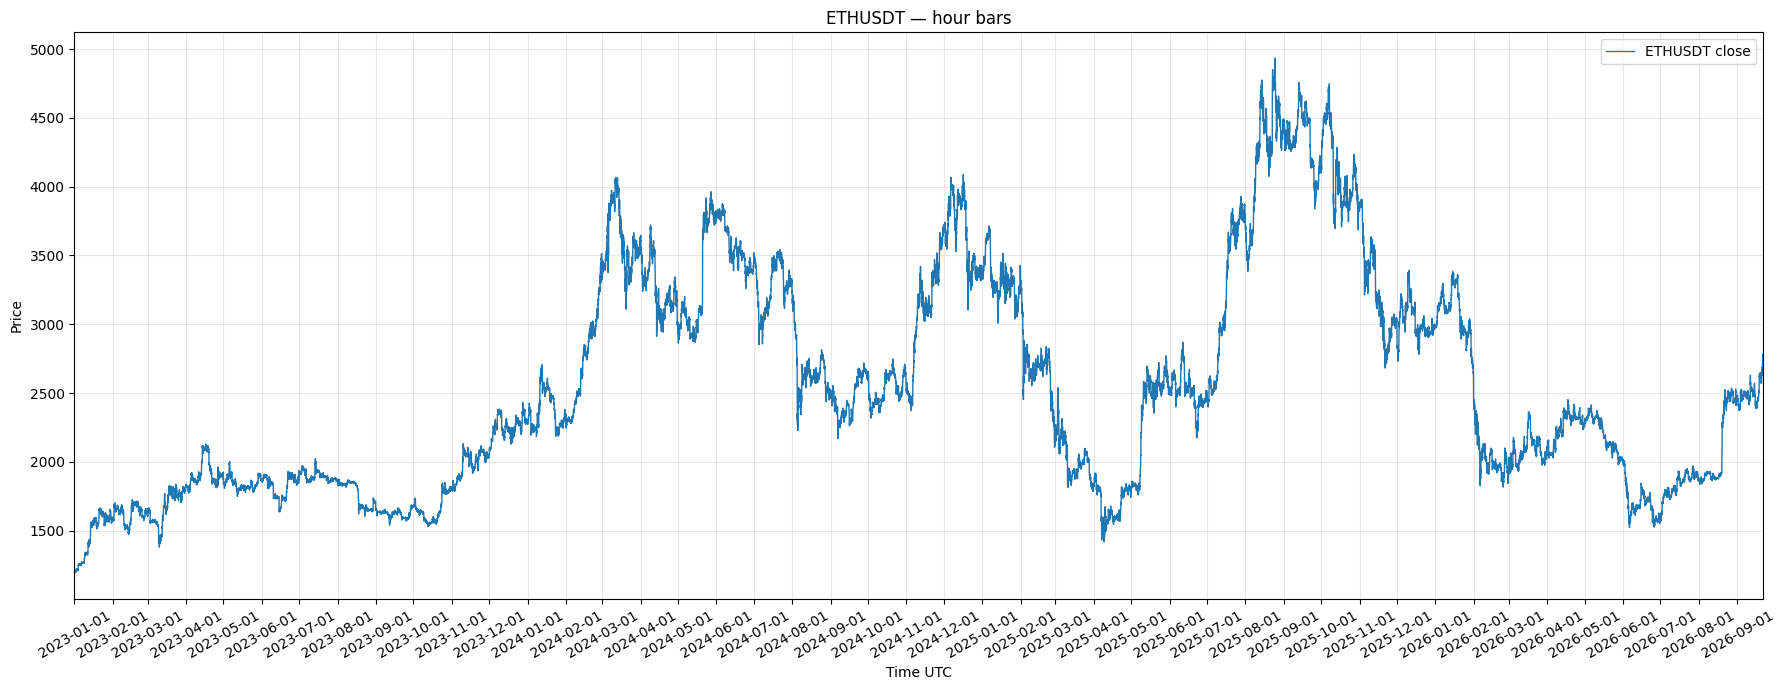

In [2]:
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    
    if "bars" not in globals() or bars.empty:
        raise RuntimeError("No bar data")
    
    fig, ax = plt.subplots(figsize=(18, 7))
    
    ax.plot(
        bars["open_time"],
        bars["close"],
        linewidth=1,
        label=f"{SYMBOL} close"
    )
    
    # Exact X-axis boundaries — no empty space
    ax.set_xlim(
        bars["open_time"].min(),
        bars["open_time"].max()
    )
    
    ax.set_title(f"{SYMBOL} — hour bars")
    ax.set_xlabel("Time UTC")
    ax.set_ylabel("Price")
    ax.grid(True, alpha=0.3)
    ax.legend()
    
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m-%d", tz=bars["open_time"].dt.tz)
    )
    
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [3]:

import numpy as np
import pandas as pd

# ==========================================
# RETROSPECTIVELY SELECTED LP RANGE
# ==========================================

DAYS = 600
HOURS = DAYS * 24

LOWER = 1500.0
UPPER = 4000.0

# Prepare historical dataset
data = (
    bars.copy()
    .sort_values("open_time")
    .drop_duplicates("open_time")
    .set_index("open_time")
)

# Last available hourly candle
AS_OF = data.index.max()

# Exactly 600 days before observation
ENTRY_DATE = AS_OF - pd.Timedelta(days=DAYS)

# Include both endpoints: 14,401 observations
history = data.loc[ENTRY_DATE:AS_OF].copy()

if len(history) != HOURS + 1:
    raise RuntimeError(
        f"Expected {HOURS + 1} bars, got {len(history)}"
    )

if not (
    history.index.to_series().diff().dropna()
    == pd.Timedelta(hours=1)
).all():
    raise RuntimeError("Missing or irregular hourly candles")

ENTRY_PRICE = float(history["close"].iloc[0])

# ==========================================
# HISTORICAL EXTREMES
# ==========================================

HIST_LOWER = float(history["low"].min())
HIST_UPPER = float(history["high"].max())

# ==========================================
# LP RANGE PARAMETERS
# ==========================================

WIDTH = (UPPER - LOWER) / ENTRY_PRICE

LOWER_DISTANCE = (
    (ENTRY_PRICE - LOWER) / ENTRY_PRICE * 100
)

UPPER_DISTANCE = (
    (UPPER - ENTRY_PRICE) / ENTRY_PRICE * 100
)

# ==========================================
# RANGE OCCUPANCY
# ==========================================

in_range = (
    (history["close"] >= LOWER) &
    (history["close"] <= UPPER)
)

TIME_IN_RANGE = in_range.mean() * 100

fully_inside = (
    (history["low"] >= LOWER) &
    (history["high"] <= UPPER)
)

FULLY_INSIDE = fully_inside.mean() * 100

hours_above = int((history["close"] > UPPER).sum())
hours_below = int((history["close"] < LOWER).sum())

# Candle touches / crosses LP boundaries
candles_outside = int((~fully_inside).sum())

# ==========================================
# RESULTS
# ==========================================

print("RETROSPECTIVELY SELECTED LP RANGE")
print("-" * 50)

print(f"Entry date:        {ENTRY_DATE}")
print(f"Observation date:  {AS_OF}")
print(f"Entry price:       ${ENTRY_PRICE:,.2f}")
print(f"Age:               {DAYS} days")
print(f"Hourly intervals:  {HOURS:,}")
print(f"Price observations:{len(history):,}")

print("\nLP RANGE")
print(f"Lower bound:       ${LOWER:,.2f}")
print(f"Upper bound:       ${UPPER:,.2f}")
print(f"Relative width:    {WIDTH:.2%}")
print(f"Distance to lower: {LOWER_DISTANCE:+.2f}%")
print(f"Distance to upper: {UPPER_DISTANCE:+.2f}%")

print("\nHISTORICAL PRICE EXTREMES")
print(f"Historical low:    ${HIST_LOWER:,.2f}")
print(f"Historical high:   ${HIST_UPPER:,.2f}")

print("\nRANGE OCCUPANCY")
print(f"Closes in range:   {TIME_IN_RANGE:.2f}%")
print(f"Fully inside:      {FULLY_INSIDE:.2f}%")
print(f"Closes above:      {hours_above:,}")
print(f"Closes below:      {hours_below:,}")
print(f"Candles crossing or outside: {candles_outside:,}")


RETROSPECTIVELY SELECTED LP RANGE
--------------------------------------------------
Entry date:        2025-01-29 23:00:00+00:00
Observation date:  2026-09-21 23:00:00+00:00
Entry price:       $3,113.90
Age:               600 days
Hourly intervals:  14,400
Price observations:14,401

LP RANGE
Lower bound:       $1,500.00
Upper bound:       $4,000.00
Relative width:    80.29%
Distance to lower: +51.83%
Distance to upper: +28.46%

HISTORICAL PRICE EXTREMES
Historical low:    $1,385.05
Historical high:   $4,956.78

RANGE OCCUPANCY
Closes in range:   88.39%
Fully inside:      88.03%
Closes above:      1,641
Closes below:      31
Candles crossing or outside: 1,724


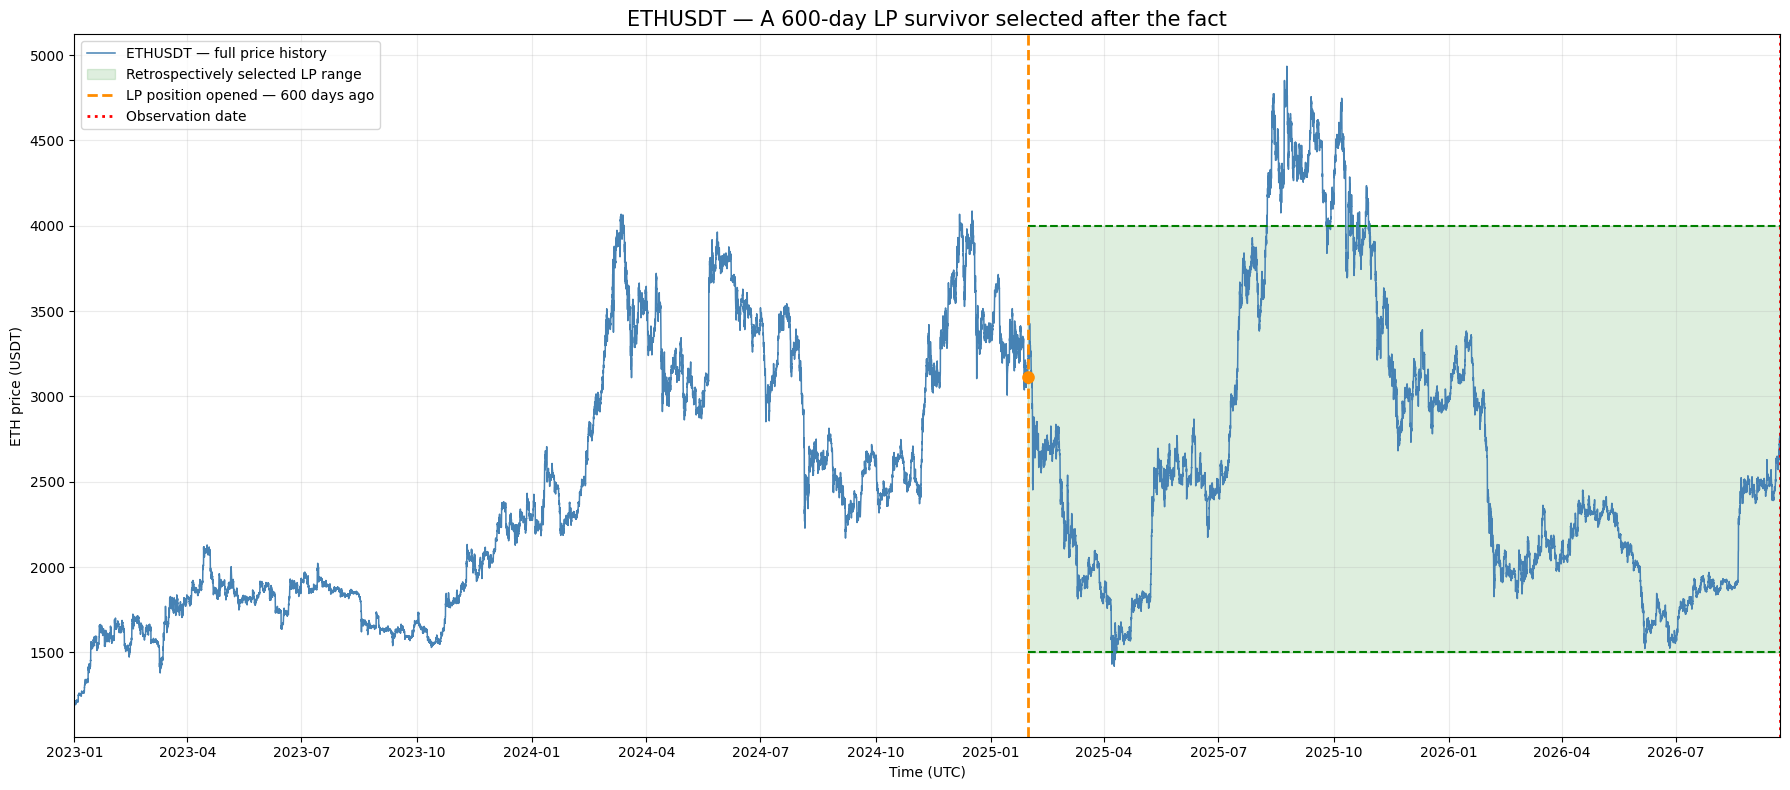

In [4]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ==========================================
# HISTORICAL LP SURVIVOR — FULL PRICE HISTORY
# ==========================================

fig, ax = plt.subplots(figsize=(18, 8))

# Full historical ETH price
ax.plot(
    data.index,
    data["close"],
    color="steelblue",
    linewidth=1.1,
    label="ETHUSDT — full price history"
)

# LP range visible only during position lifetime
ax.fill_between(
    history.index,
    LOWER,
    UPPER,
    color="green",
    alpha=0.13,
    label="Retrospectively selected LP range"
)

# Range boundaries from hypothetical entry onward
ax.hlines(
    [LOWER, UPPER],
    xmin=ENTRY_DATE,
    xmax=AS_OF,
    colors="green",
    linestyles="--",
    linewidth=1.5
)

# Hypothetical position opening date
ax.axvline(
    ENTRY_DATE,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="LP position opened — 600 days ago"
)

ax.scatter(
    ENTRY_DATE,
    ENTRY_PRICE,
    color="darkorange",
    s=65,
    zorder=5
)

# Observation date
ax.axvline(
    AS_OF,
    color="red",
    linestyle=":",
    linewidth=2,
    label="Observation date"
)

ax.set_title(
    "ETHUSDT — A 600-day LP survivor selected after the fact",
    fontsize=15
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("ETH price (USDT)")

ax.set_xlim(
    data.index.min(),
    AS_OF
)

ax.grid(alpha=0.25)
ax.legend(loc="upper left")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m", tz=timezone.utc)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Generated 10000 paths with 24h blocks
Generated 10000 paths with 168h blocks
Generated 10000 paths with 720h blocks

VALIDATION PASSED
Period: 2025-01-29 23:00:00+00:00 to 2026-09-21 22:00:00+00:00
Hours: 14400
Original start: $3,113.90
Original end: $2,779.21
Paths per block size: 10000
All terminal prices verified.


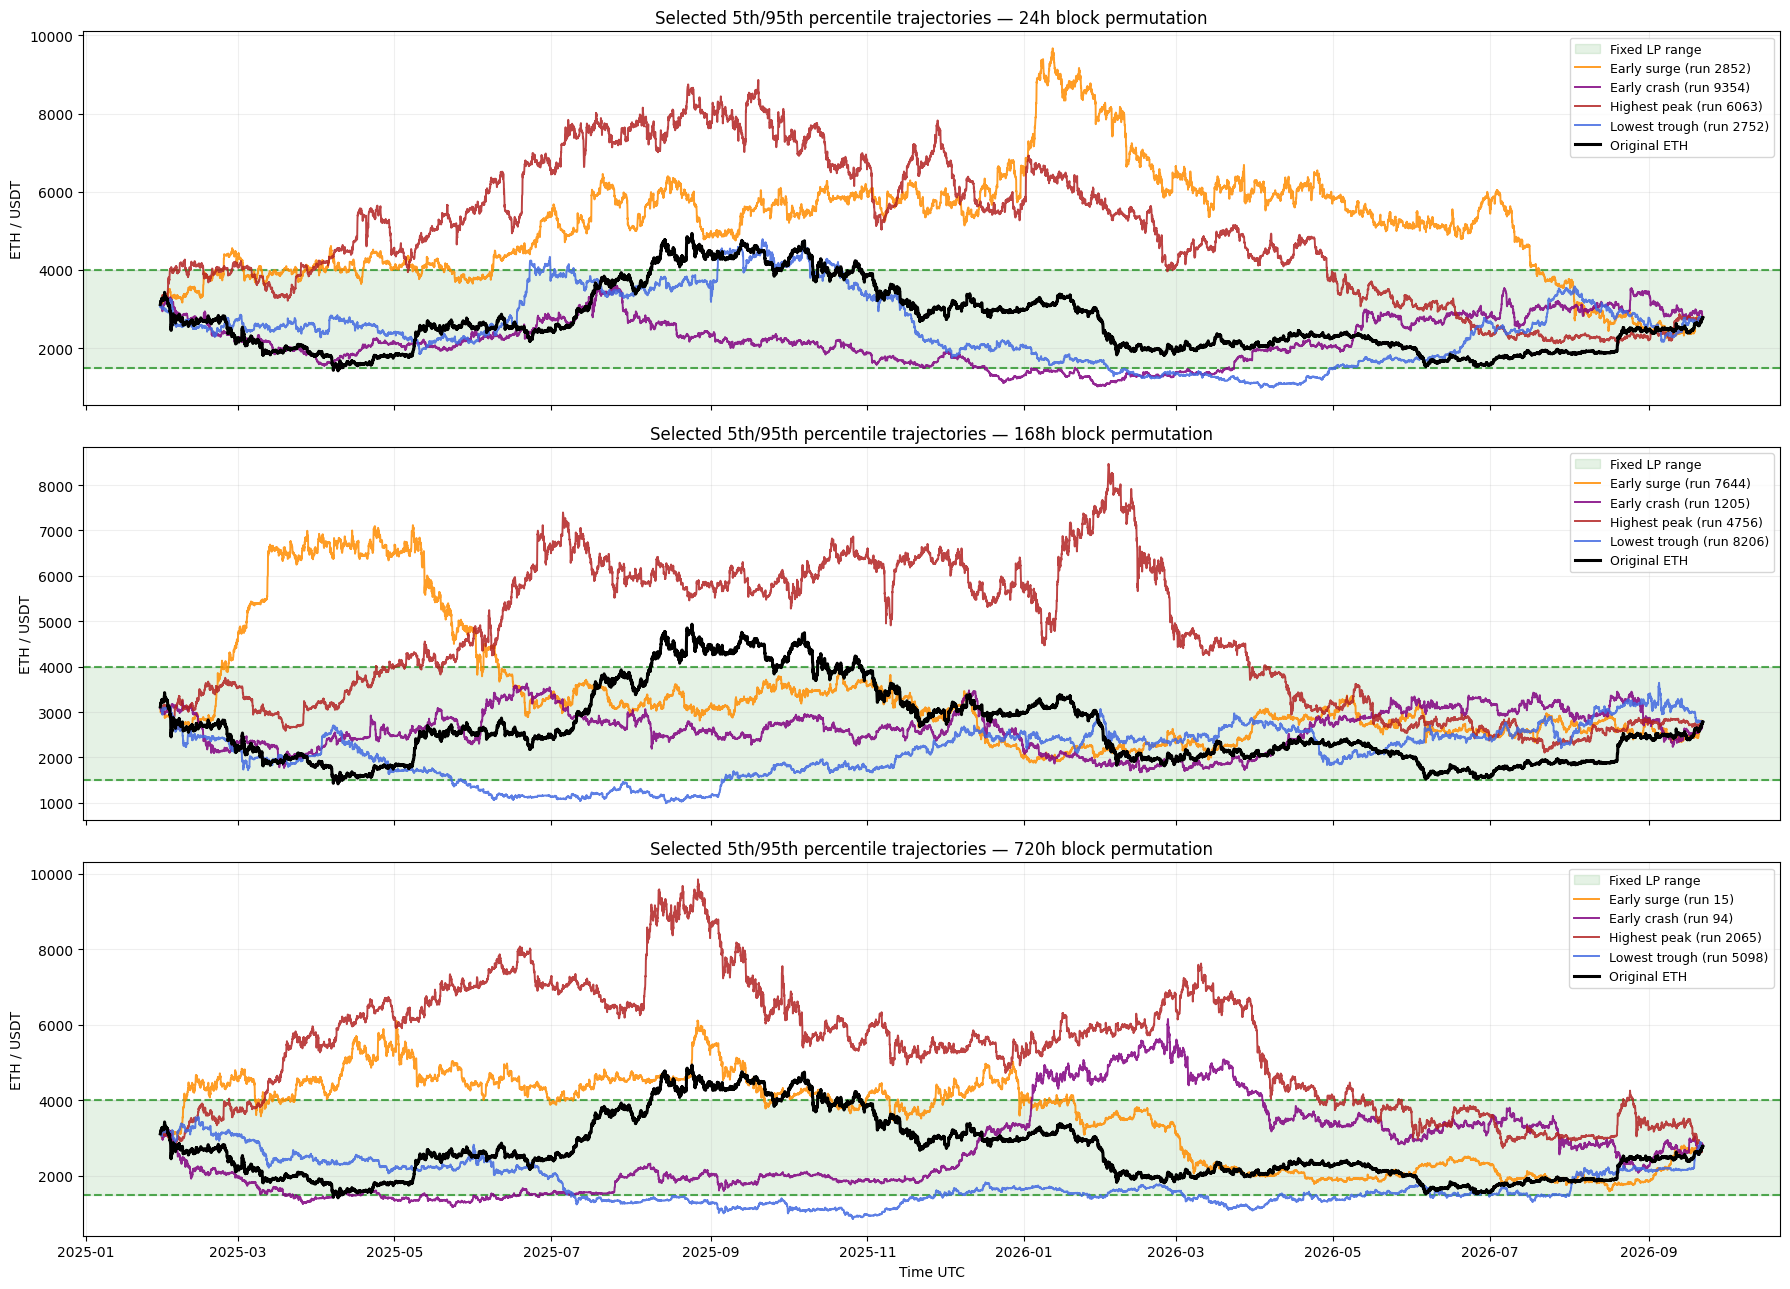


SELECTED PATH COMPARISON


,Block hours,Scenario,Run ID,First 30d max,First 30d min,Full max,Full min,Time in range (%)
0,24,Early surge,2852,4558.41,3100.33,9671.47,2257.10,22.45
1,24,Early crash,9354,3300.30,2135.26,3591.12,1020.04,83.79
2,24,Highest peak,6063,4265.75,3091.69,8862.10,2118.45,30.47
3,24,Lowest trough,2752,3256.44,2291.10,4788.54,986.52,77.37
4,168,Early surge,7644,4602.51,2629.56,7115.83,1883.92,82.47
5,168,Early crash,1205,3242.55,2099.84,3628.85,1671.39,100.00
6,168,Highest peak,4756,3755.21,2810.29,8466.24,2109.05,44.65
7,168,Lowest trough,8206,3147.94,2130.17,3643.87,992.26,82.48
8,720,Early surge,15,4799.00,3015.24,6109.62,1591.08,52.12
9,720,Early crash,94,3205.11,1926.22,6154.21,1170.81,71.91


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# EXPERIMENT: SAME RETURNS, DIFFERENT ORDER
# SELECTED 5TH / 95TH PERCENTILE PRICE PATHS
# ==================================================

DAYS = 600
HOURS = DAYS * 24

N_PATHS = 10000
BLOCK_SIZES = [24, 168, 720]  # 1, 7, 30 days
SEED = 42

EARLY_DAYS = 30
EARLY_HOURS = EARLY_DAYS * 24

rng = np.random.default_rng(SEED)

# ==================================================
# 1. PREPARE HISTORICAL DATA
# ==================================================

source = (
    bars.loc[
        (bars["open_time"] >= ENTRY_DATE) &
        (bars["open_time"] < AS_OF)
    ]
    .sort_values("open_time")
    .reset_index(drop=True)
    .copy()
)

if len(source) != HOURS:
    raise RuntimeError("Incomplete 600-day history")

times = source["open_time"]
prices = source["close"].to_numpy(dtype=float)

if np.any(prices <= 0):
    raise ValueError("Prices must be positive")

dt = times.diff().dropna()

if not (dt == pd.Timedelta(hours=1)).all():
    raise RuntimeError("Missing or irregular hourly candles")

P0 = float(prices[0])
original_path = prices.copy()

# Real observed hourly log returns
returns = np.diff(np.log(prices))


# ==================================================
# 2. BLOCK PERMUTATION FUNCTIONS
# ==================================================

def permute_blocks(returns, block_hours, rng):
    """
    Split observed log returns into consecutive blocks.
    Shuffle blocks without replacement.
    Preserve the order inside each block.
    """

    blocks = [
        returns[i:i + block_hours]
        for i in range(0, len(returns), block_hours)
    ]

    order = rng.permutation(len(blocks))

    return np.concatenate([
        blocks[i] for i in order
    ])


def reconstruct_path(start_price, log_returns):

    cumulative = np.concatenate([
        [0.0],
        np.cumsum(log_returns)
    ])

    return start_price * np.exp(cumulative)


# ==================================================
# 3. GENERATE 10,000 PATHS PER BLOCK SIZE
# ==================================================

simulations = {}

for block_size in BLOCK_SIZES:

    paths = np.empty(
        (N_PATHS, HOURS),
        dtype=float
    )

    for i in range(N_PATHS):

        shuffled = permute_blocks(
            returns,
            block_size,
            rng
        )

        paths[i] = reconstruct_path(
            P0,
            shuffled
        )

    simulations[block_size] = paths

    print(
        f"Generated {N_PATHS} paths "
        f"with {block_size}h blocks"
    )


# ==================================================
# 4. VALIDATION
# ==================================================

for block_size, paths in simulations.items():

    assert paths.shape == (N_PATHS, HOURS)

    assert np.allclose(paths[:, 0], P0)

    assert np.allclose(
        paths[:, -1],
        original_path[-1]
    )

print("\nVALIDATION PASSED")
print("Period:", times.iloc[0], "to", times.iloc[-1])
print("Hours:", HOURS)
print(f"Original start: ${P0:,.2f}")
print(f"Original end: ${prices[-1]:,.2f}")
print("Paths per block size:", N_PATHS)
print("All terminal prices verified.")


# ==================================================
# 5. SELECT PATHS BY PERCENTILES
# ==================================================

def closest_percentile_index(values, percentile):
    """
    Find the actual simulated path closest
    to the requested percentile.
    """

    target = np.percentile(values, percentile)

    return int(
        np.argmin(np.abs(values - target))
    )


selected_paths = {}

for block_size in BLOCK_SIZES:

    paths = simulations[block_size]

    early_prices = paths[:, :EARLY_HOURS + 1]

    # Price extremes during first 30 days
    early_max = early_prices.max(axis=1)
    early_min = early_prices.min(axis=1)

    # Price extremes over full 600 days
    full_max = paths.max(axis=1)
    full_min = paths.min(axis=1)

    idx_early_surge = closest_percentile_index(
        early_max, 95
    )

    idx_early_crash = closest_percentile_index(
        early_min, 5
    )

    idx_highest = closest_percentile_index(
        full_max, 95
    )

    idx_lowest = closest_percentile_index(
        full_min, 5
    )

    selected_paths[block_size] = [
        ("Early surge", idx_early_surge, "darkorange"),
        ("Early crash", idx_early_crash, "purple"),
        ("Highest peak", idx_highest, "firebrick"),
        ("Lowest trough", idx_lowest, "royalblue")
    ]


# ==================================================
# 6. VISUALIZATION — SELECTED PRICE PATHS
# ==================================================

fig, axes = plt.subplots(
    len(BLOCK_SIZES), 1,
    figsize=(18, 13),
    sharex=True
)

for ax, block_size in zip(axes, BLOCK_SIZES):

    paths = simulations[block_size]
    selections = selected_paths[block_size]

    # Fixed LP range
    ax.axhspan(
        LOWER,
        UPPER,
        color="green",
        alpha=0.10,
        label="Fixed LP range"
    )

    ax.axhline(
        LOWER,
        color="green",
        linestyle="--",
        alpha=0.65
    )

    ax.axhline(
        UPPER,
        color="green",
        linestyle="--",
        alpha=0.65
    )

    # Selected alternative price paths
    for label, idx, color in selections:

        path = paths[idx]

        ax.plot(
            times,
            path,
            color=color,
            alpha=0.85,
            linewidth=1.4,
            label=f"{label} (run {idx})"
        )

    # Real ETH price
    ax.plot(
        times,
        original_path,
        color="black",
        linewidth=2.2,
        label="Original ETH",
        zorder=10
    )

    ax.set_title(
        f"Selected 5th/95th percentile trajectories "
        f"— {block_size}h block permutation"
    )

    ax.set_ylabel("ETH / USDT")
    ax.grid(alpha=0.20)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Time UTC")

plt.tight_layout()
plt.show()


# ==================================================
# 7. SELECTION STATISTICS
# ==================================================

records = []

for block_size, selections in selected_paths.items():

    paths = simulations[block_size]

    for label, idx, color in selections:

        path = paths[idx]

        inside = (
            (path >= LOWER) &
            (path <= UPPER)
        )

        records.append({
            "Block hours": block_size,
            "Scenario": label,
            "Run ID": idx,
            "First 30d max": path[:EARLY_HOURS+1].max(),
            "First 30d min": path[:EARLY_HOURS+1].min(),
            "Full max": path.max(),
            "Full min": path.min(),
            "Time in range (%)": inside.mean() * 100
        })

extreme_results = pd.DataFrame(records)

print("\nSELECTED PATH COMPARISON")

display(
    extreme_results.round(2)
)


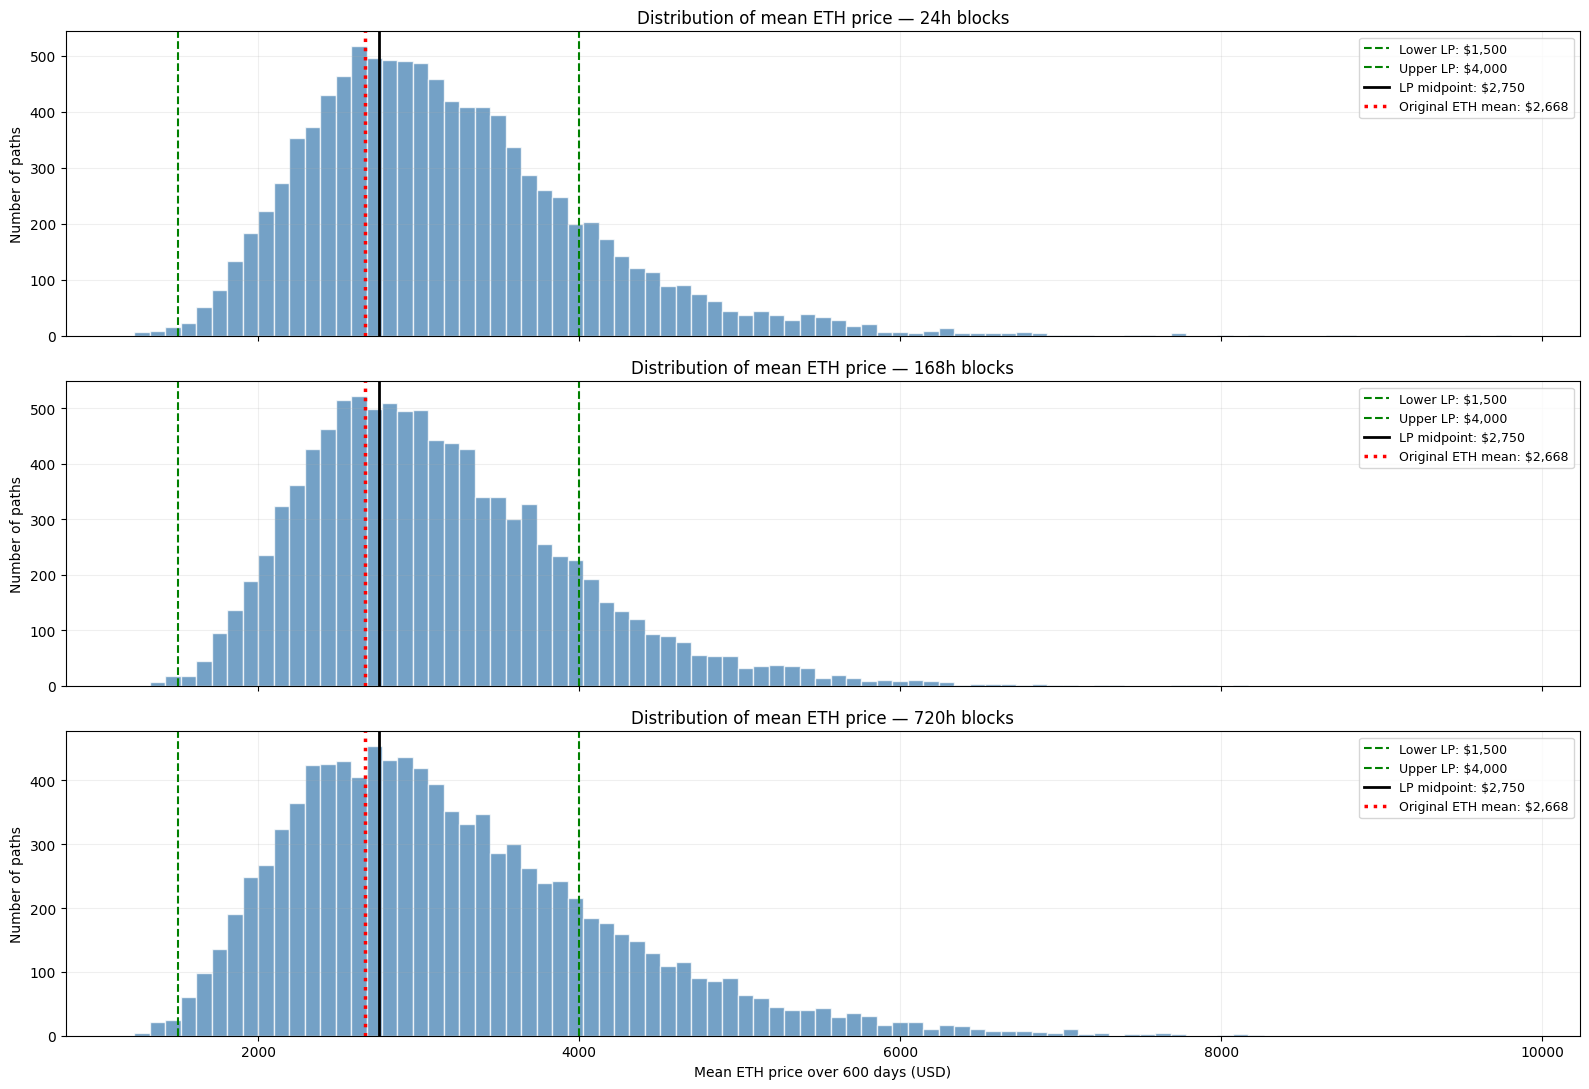

In [6]:

# ==================================================
# DISTRIBUTION OF MEAN ETH PRICE ACROSS PATHS
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

MIDPOINT = (LOWER + UPPER) / 2

# Mean price of the actual ETH path
original_mean = original_path.mean()

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 11),
    sharex=True
)

# Common bins for comparable histograms
all_means = np.concatenate([
    simulations[b].mean(axis=1)
    for b in BLOCK_SIZES
])

bins = np.linspace(
    all_means.min(),
    all_means.max(),
    90
)

for ax, block_size in zip(axes, BLOCK_SIZES):

    paths = simulations[block_size]

    # One mean price per simulated path
    mean_prices = paths.mean(axis=1)

    ax.hist(
        mean_prices,
        bins=bins,
        color="steelblue",
        alpha=0.75,
        edgecolor="white"
    )

    # Fixed LP boundaries
    ax.axvline(
        LOWER,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label=f"Lower LP: ${LOWER:,.0f}"
    )

    ax.axvline(
        UPPER,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label=f"Upper LP: ${UPPER:,.0f}"
    )

    # Center of LP range
    ax.axvline(
        MIDPOINT,
        color="black",
        linewidth=2,
        label=f"LP midpoint: ${MIDPOINT:,.0f}"
    )

    # Original historical ETH
    ax.axvline(
        original_mean,
        color="red",
        linestyle=":",
        linewidth=2.5,
        label=f"Original ETH mean: ${original_mean:,.0f}"
    )

    ax.set_title(
        f"Distribution of mean ETH price — {block_size}h blocks"
    )

    ax.set_ylabel("Number of paths")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

axes[-1].set_xlabel(
    "Mean ETH price over 600 days (USD)"
)

plt.tight_layout()
plt.show()


In [9]:

import numpy as np

# ==========================================
# RESTORE UNISWAP V3 LP MODEL AND RISK RESULTS
# ==========================================

INITIAL_CAPITAL = 10_000.0
LOWER = 1500.0
UPPER = 4000.0

sqrt_L = np.sqrt(LOWER)
sqrt_U = np.sqrt(UPPER)

def lp_amounts(price):
    p = np.asarray(price, dtype=float)

    if np.any(p <= 0):
        raise ValueError("Prices must be positive")

    sqrt_p = np.sqrt(np.clip(p, LOWER, UPPER))

    eth = 1.0 / sqrt_p - 1.0 / sqrt_U
    usdt = sqrt_p - sqrt_L

    return eth, usdt


# Entry price must match simulated paths
P0 = float(simulations[BLOCK_SIZES[0]][0, 0])

eth0, usdt0 = lp_amounts(P0)

LIQUIDITY = INITIAL_CAPITAL / (
    P0 * float(eth0) + float(usdt0)
)


def lp_value(price):
    p = np.asarray(price, dtype=float)

    eth, usdt = lp_amounts(p)

    return LIQUIDITY * (p * eth + usdt)


# ==========================================
# REBUILD RISK RESULTS
# ==========================================

risk_results = {}

for block_size in BLOCK_SIZES:

    paths = simulations[block_size]

    min_prices = paths.min(axis=1)
    min_capital = lp_value(min_prices)

    loss_pct = (
        1.0 - min_capital / INITIAL_CAPITAL
    ) * 100.0

    risk_results[block_size] = {
        "min_price": min_prices,
        "min_capital": min_capital,
        "loss_pct": loss_pct
    }


original_min_capital = float(
    lp_value(original_path.min())
)

historical_loss = (
    1.0 - original_min_capital / INITIAL_CAPITAL
) * 100.0


# ==========================================
# VALIDATION
# ==========================================

assert np.isclose(lp_value(P0), INITIAL_CAPITAL)

assert np.isclose(original_path[0], P0)

for b in BLOCK_SIZES:
    assert len(risk_results[b]["loss_pct"]) == len(simulations[b])

print("LP MODEL RESTORED")
print("-" * 45)
print(f"Entry ETH price:       ${P0:,.2f}")
print(f"Initial capital:       ${INITIAL_CAPITAL:,.2f}")
print(f"LP range:              ${LOWER:,.0f} - ${UPPER:,.0f}")
print(f"Historical min capital:${original_min_capital:,.2f}")
print(f"Historical loss:       {historical_loss:.2f}%")

for b in BLOCK_SIZES:
    print(
        f"{b}h: {len(risk_results[b]['loss_pct']):,} paths restored"
    )


LP MODEL RESTORED
---------------------------------------------
Entry ETH price:       $3,113.90
Initial capital:       $10,000.00
LP range:              $1,500 - $4,000
Historical min capital:$6,006.86
Historical loss:       39.93%
24h: 10,000 paths restored
168h: 10,000 paths restored
720h: 10,000 paths restored


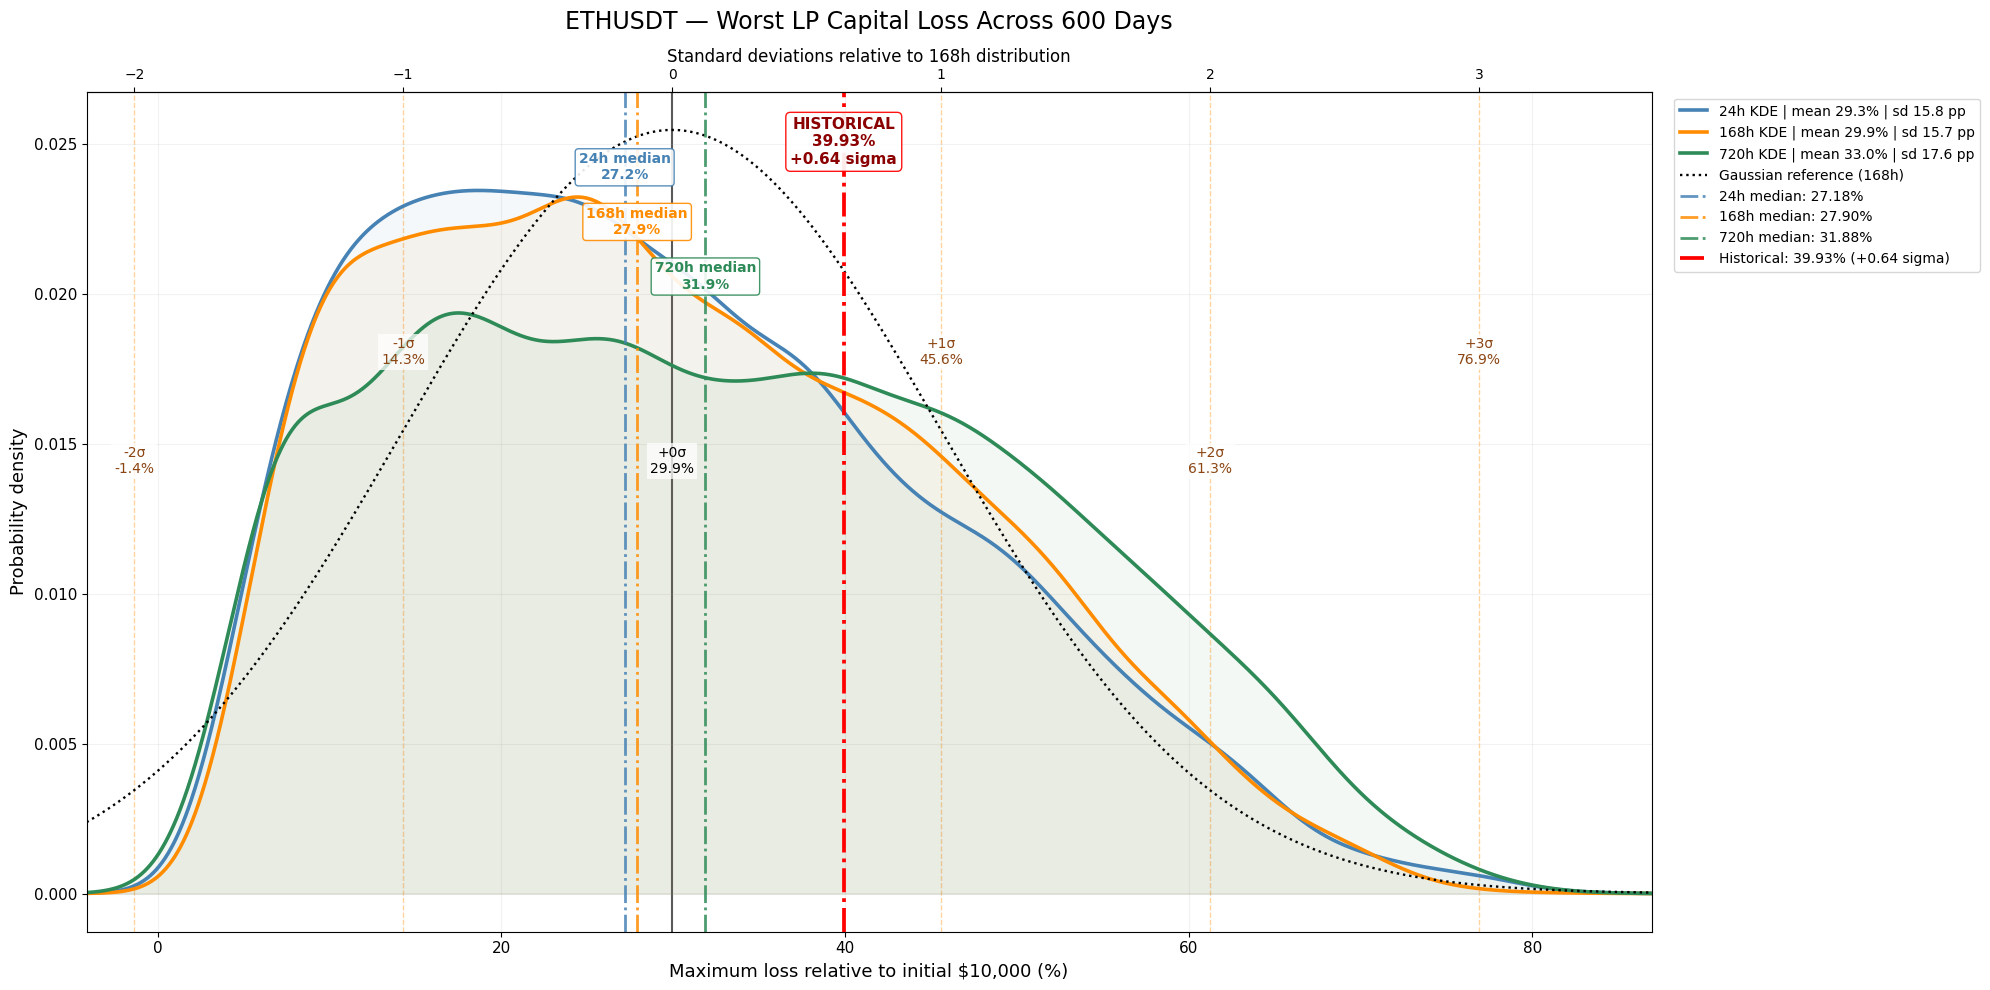


DISTRIBUTION STATISTICS


,Block,Mean (%),Median (%),Sigma (pp),P95 loss (%),P99 loss (%),Worst loss (%),P(loss > history) %
0,24h,29.33,27.18,15.81,58.23,68.60,82.81,25.21
1,168h,29.94,27.90,15.66,57.99,67.09,81.05,27.55
2,720h,33.04,31.88,17.60,63.38,71.18,80.88,35.81



EMPIRICAL COVERAGE OF 168h SIGMA BANDS


,Block,Reference interval,Lower loss (%),Upper loss (%),Inside interval (%),Above upper (%),Normal inside (%)
0,24h,+/- 1 sigma,14.29,45.60,62.79,17.50,68.27
1,24h,+/- 2 sigma,-1.37,61.25,96.69,3.31,95.45
2,24h,+/- 3 sigma,-17.03,76.91,99.87,0.13,99.73
3,168h,+/- 1 sigma,14.29,45.60,62.71,18.58,68.27
4,168h,+/- 2 sigma,-1.37,61.25,97.06,2.94,95.45
5,168h,+/- 3 sigma,-17.03,76.91,99.97,0.03,99.73
6,720h,+/- 1 sigma,14.29,45.60,56.63,26.58,68.27
7,720h,+/- 2 sigma,-1.37,61.25,93.37,6.63,95.45
8,720h,+/- 3 sigma,-17.03,76.91,99.87,0.13,99.73



ADVERSE SIGMA THRESHOLDS — 168h REFERENCE


,Level,Loss (%),Capital remaining ($),P168(loss >= threshold) (%)
0,+0 sigma,29.94,7005.95,45.79
1,+1 sigma,45.60,5440.40,18.58
2,+2 sigma,61.25,3874.86,2.94
3,+3 sigma,76.91,2309.32,0.03


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm

# =====================================================
# LP CAPITAL RISK — ENHANCED DISTRIBUTION
# =====================================================

REFERENCE_BLOCK = 168

COLORS = {
    24: "steelblue",
    168: "darkorange",
    720: "seagreen"
}

losses = {
    b: np.asarray(risk_results[b]["loss_pct"], dtype=float)
    for b in BLOCK_SIZES
}

historical_loss = 100 * (
    1 - original_min_capital / INITIAL_CAPITAL
)

stats = {}

for b, values in losses.items():
    if not np.isfinite(values).all():
        raise ValueError(f"Non-finite losses in {b}h")

    stats[b] = {
        "mean": np.mean(values),
        "sigma": np.std(values, ddof=1),
        "median": np.median(values),
        "p95": np.percentile(values, 95),
        "p99": np.percentile(values, 99),
        "max": np.max(values)
    }

mu_ref = stats[REFERENCE_BLOCK]["mean"]
sigma_ref = stats[REFERENCE_BLOCK]["sigma"]

if sigma_ref <= 0:
    raise ValueError("Reference sigma must be positive")

# =====================================================
# SIGMA BOUNDARIES
# =====================================================

sigma_levels = {
    k: mu_ref + k * sigma_ref
    for k in range(-3, 4)
}

# =====================================================
# GRAPH
# =====================================================

fig, ax = plt.subplots(figsize=(20, 10))

all_losses = np.concatenate(list(losses.values()))

xmin = min(0, all_losses.min(), historical_loss)
xmax = max(
    all_losses.max(),
    historical_loss,
    sigma_levels[3]
)

margin = (xmax - xmin) * 0.05

x = np.linspace(
    xmin - margin,
    xmax + margin,
    1600
)

# =====================================================
# 1. EMPIRICAL KDE DISTRIBUTIONS
# =====================================================

for b in BLOCK_SIZES:

    values = losses[b]
    color = COLORS[b]

    kde = gaussian_kde(values)
    density = kde(x)

    ax.plot(
        x, density,
        color=color,
        lw=2.6,
        label=(
            f"{b}h KDE | "
            f"mean {stats[b]['mean']:.1f}% | "
            f"sd {stats[b]['sigma']:.1f} pp"
        )
    )

    ax.fill_between(
        x, density,
        color=color,
        alpha=0.055
    )

# =====================================================
# 2. GAUSSIAN REFERENCE
# =====================================================

ax.plot(
    x,
    norm.pdf(x, loc=mu_ref, scale=sigma_ref),
    color="black",
    linestyle=":",
    linewidth=1.7,
    label="Gaussian reference (168h)"
)

# =====================================================
# 3. SIGMA BOUNDARIES AND NUMERIC LABELS
# =====================================================

for k, value in sigma_levels.items():

    if not (x.min() <= value <= x.max()):
        continue

    is_mean = (k == 0)

    ax.axvline(
        value,
        color="black" if is_mean else "darkorange",
        linestyle="-" if is_mean else "--",
        lw=1.5 if is_mean else 1.0,
        alpha=0.65 if is_mean else 0.38,
        zorder=0
    )

    # Place labels at alternating heights
    y_pos = 0.56 if k % 2 == 0 else 0.69

    ax.text(
        value,
        y_pos,
        f"{k:+d}σ\n{value:.1f}%",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="center",
        fontsize=10,
        color="black" if is_mean else "saddlebrown",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.75,
            pad=2
        )
    )

# =====================================================
# 4. MEDIANS OF ALL THREE DISTRIBUTIONS
# =====================================================

for i, b in enumerate(BLOCK_SIZES):

    median = stats[b]["median"]
    color = COLORS[b]

    ax.axvline(
        median,
        color=color,
        linestyle="-.",
        linewidth=2.0,
        alpha=0.85,
        label=f"{b}h median: {median:.2f}%"
    )

    ax.text(
        median,
        0.91 - i * 0.065,
        f"{b}h median\n{median:.1f}%",
        color=color,
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center",
        transform=ax.get_xaxis_transform(),
        bbox=dict(
            facecolor="white",
            edgecolor=color,
            alpha=0.90,
            boxstyle="round,pad=0.25"
        )
    )

# =====================================================
# 5. HISTORICAL LOSS
# =====================================================

historical_z = (
    historical_loss - mu_ref
) / sigma_ref

ax.axvline(
    historical_loss,
    color="red",
    linestyle="-.",
    linewidth=2.7,
    label=(
        f"Historical: {historical_loss:.2f}% "
        f"({historical_z:+.2f} sigma)"
    )
)

ax.text(
    historical_loss,
    0.97,
    f"HISTORICAL\n{historical_loss:.2f}%\n"
    f"{historical_z:+.2f} sigma",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=11,
    color="darkred",
    fontweight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="red",
        alpha=0.92,
        boxstyle="round,pad=0.3"
    )
)

# =====================================================
# 6. SECONDARY SIGMA AXIS
# =====================================================

def loss_to_sigma(value):
    return (value - mu_ref) / sigma_ref

def sigma_to_loss(z):
    return mu_ref + z * sigma_ref

ax_top = ax.secondary_xaxis(
    "top",
    functions=(loss_to_sigma, sigma_to_loss)
)

ax_top.set_xticks(np.arange(-3, 4))

ax_top.set_xlabel(
    "Standard deviations relative to 168h distribution",
    fontsize=12
)

# =====================================================
# 7. FORMATTING
# =====================================================

ax.set_xlim(x.min(), x.max())

ax.set_title(
    "ETHUSDT — Worst LP Capital Loss Across 600 Days",
    fontsize=17,
    pad=14
)

ax.set_xlabel(
    "Maximum loss relative to initial $10,000 (%)",
    fontsize=13
)

ax.set_ylabel("Probability density", fontsize=13)

ax.tick_params(labelsize=11)
ax.grid(alpha=0.16)
ax.set_axisbelow(True)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=10
)

plt.tight_layout()
plt.show()

# =====================================================
# 8. DISTRIBUTION SUMMARY
# =====================================================

records = []

for b in BLOCK_SIZES:

    v = losses[b]

    records.append({
        "Block": f"{b}h",
        "Mean (%)": v.mean(),
        "Median (%)": np.median(v),
        "Sigma (pp)": v.std(ddof=1),
        "P95 loss (%)": np.percentile(v, 95),
        "P99 loss (%)": np.percentile(v, 99),
        "Worst loss (%)": v.max(),
        "P(loss > history) %":
            np.mean(v > historical_loss) * 100
    })

summary = pd.DataFrame(records)

print("\nDISTRIBUTION STATISTICS")
display(summary.round(2))

# =====================================================
# 9. EMPIRICAL SIGMA PROBABILITIES
# =====================================================

records = []

for b in BLOCK_SIZES:

    v = losses[b]

    # Same 168h reference boundaries for all models
    for k in (1, 2, 3):

        lower = mu_ref - k * sigma_ref
        upper = mu_ref + k * sigma_ref

        within = np.mean(
            (v >= lower) & (v <= upper)
        ) * 100

        beyond_upper = np.mean(v > upper) * 100

        records.append({
            "Block": f"{b}h",
            "Reference interval": f"+/- {k} sigma",
            "Lower loss (%)": lower,
            "Upper loss (%)": upper,
            "Inside interval (%)": within,
            "Above upper (%)": beyond_upper,
            "Normal inside (%)":
                (2 * norm.cdf(k) - 1) * 100
        })

sigma_table = pd.DataFrame(records)

print("\nEMPIRICAL COVERAGE OF 168h SIGMA BANDS")
display(sigma_table.round(2))

# =====================================================
# 10. CAPITAL REMAINING AT ADVERSE THRESHOLDS
# =====================================================

records = []

for k in (0, 1, 2, 3):

    loss_threshold = mu_ref + k * sigma_ref

    records.append({
        "Level": f"+{k} sigma",
        "Loss (%)": loss_threshold,
        "Capital remaining ($)":
            INITIAL_CAPITAL * (1 - loss_threshold / 100),
        "P168(loss >= threshold) (%)":
            np.mean(
                losses[REFERENCE_BLOCK] >= loss_threshold
            ) * 100
    })

capital_table = pd.DataFrame(records)

print("\nADVERSE SIGMA THRESHOLDS — 168h REFERENCE")
display(capital_table.round(2))


In [11]:
for b in BLOCK_SIZES:
    for threshold in [50, 60, 70, 80]:
        p = np.mean(losses[b] >= threshold) * 100
        print(f"{b}h | Loss >= {threshold}%: {p:.2f}%")

24h | Loss >= 50%: 12.07%
24h | Loss >= 60%: 4.11%
24h | Loss >= 70%: 0.80%
24h | Loss >= 80%: 0.02%
168h | Loss >= 50%: 12.60%
168h | Loss >= 60%: 3.58%
168h | Loss >= 70%: 0.44%
168h | Loss >= 80%: 0.01%
720h | Loss >= 50%: 19.79%
720h | Loss >= 60%: 7.84%
720h | Loss >= 70%: 1.33%
720h | Loss >= 80%: 0.02%


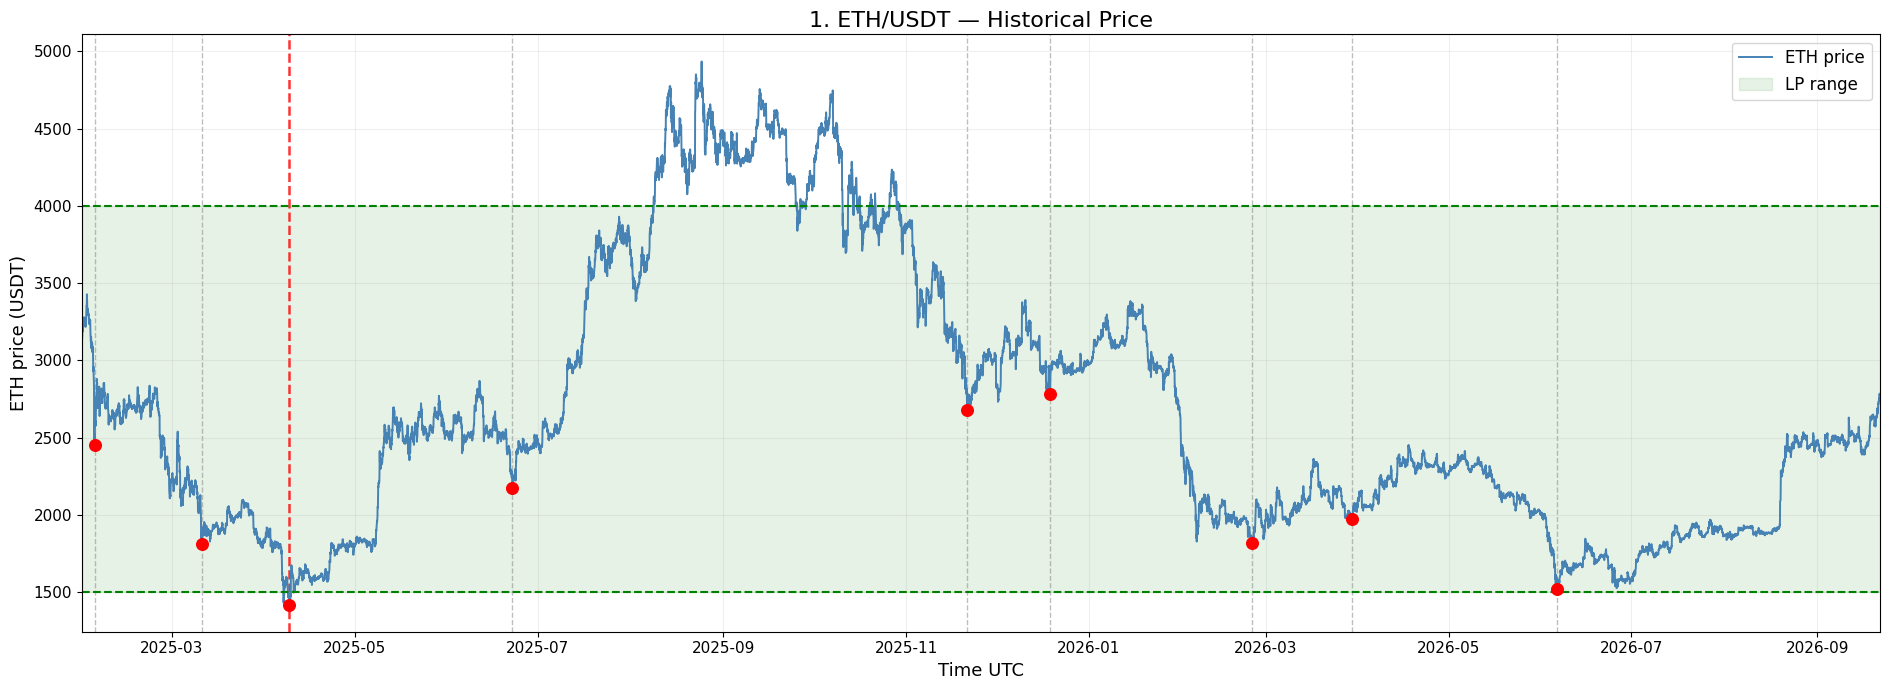

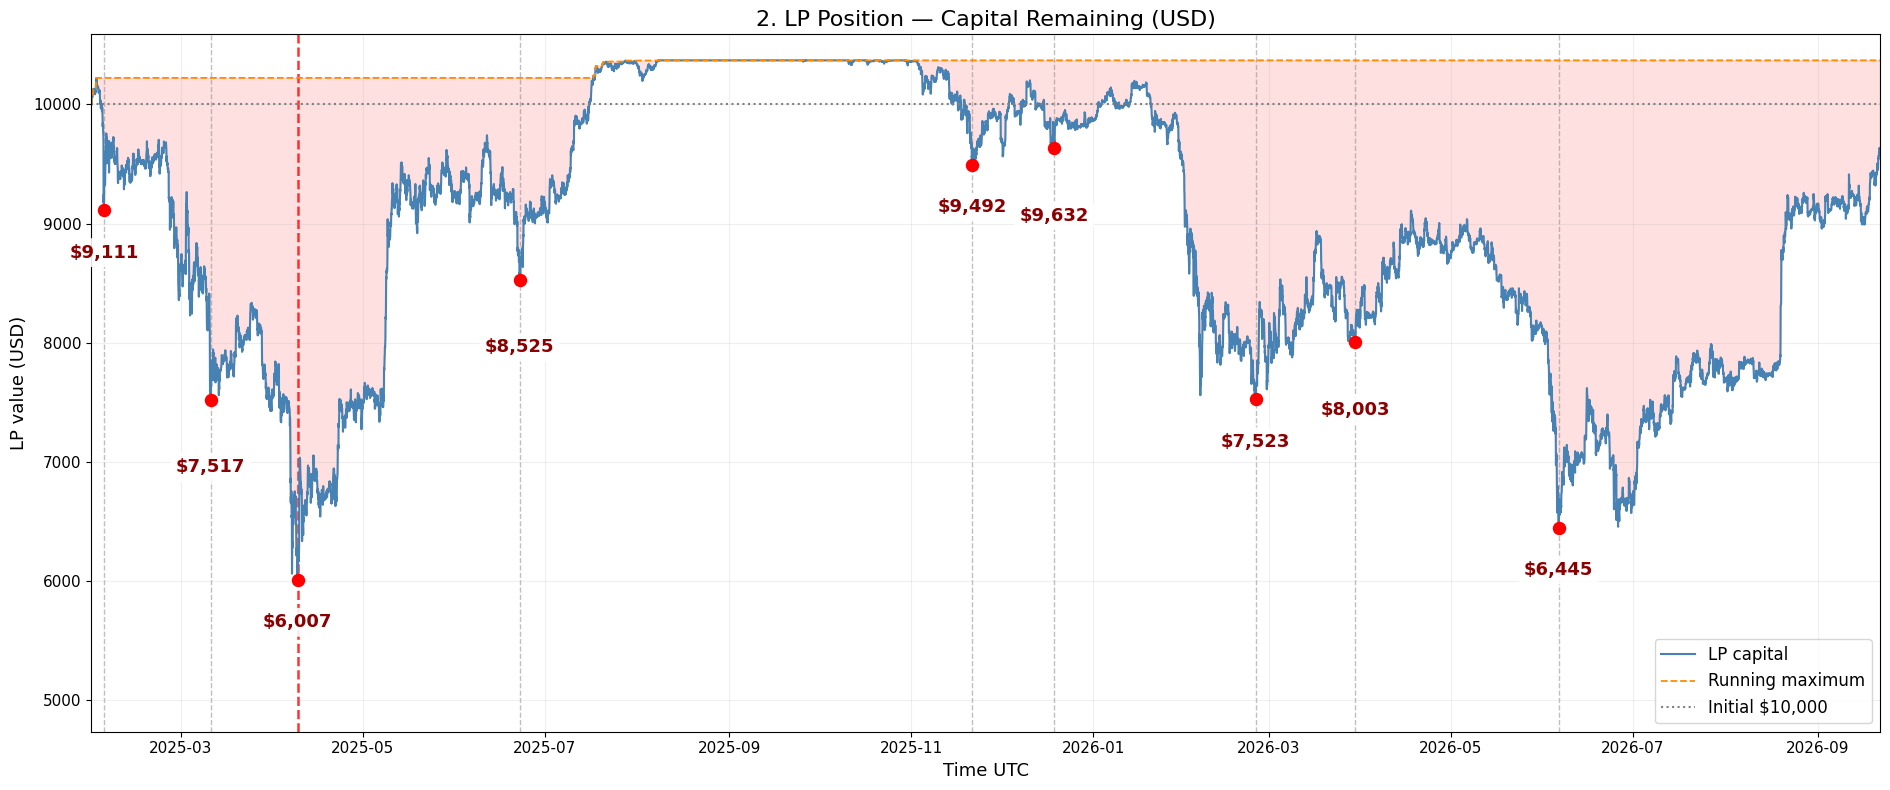

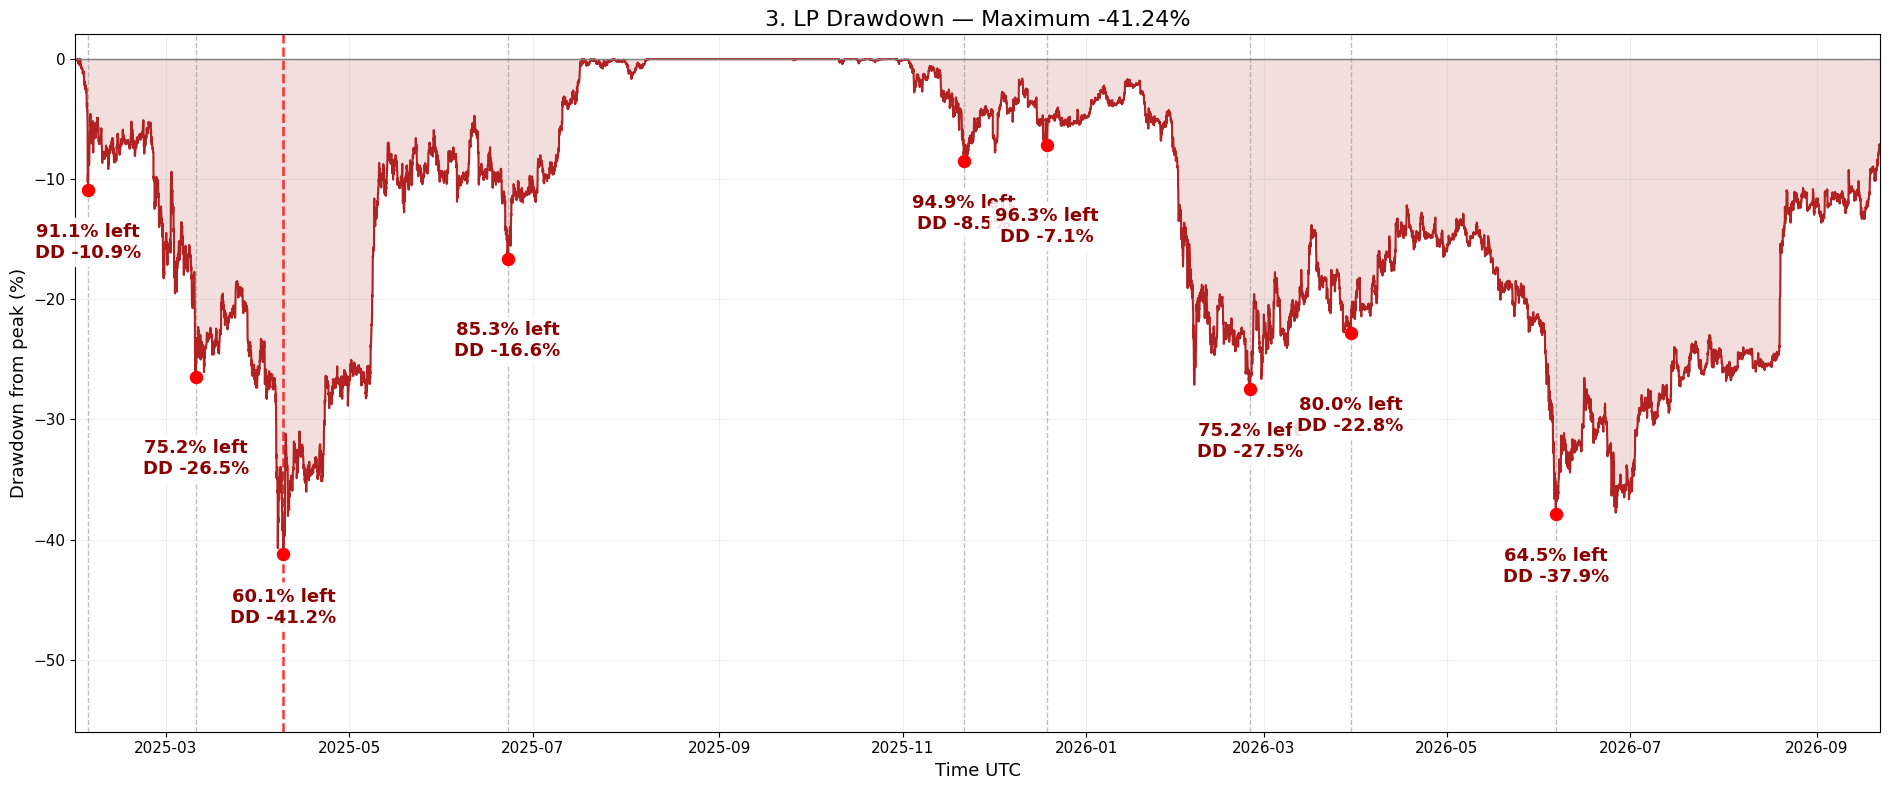

In [12]:

from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# THREE SEPARATE LP CHARTS WITH EXTREME LINES
# ==========================================

MIN_SPACING_DAYS = 20
MIN_PROMINENCE_PCT = 4.0
MAX_LABELS = 12

LABEL_FONT_SIZE = 13
TITLE_FONT_SIZE = 16
AXIS_FONT_SIZE = 13

# ==========================================
# RESTORE REAL HISTORICAL ETH DATA
# ==========================================

prices = history["close"].to_numpy(dtype=float)

capital = lp_value(prices)

running_peak = np.maximum.accumulate(capital)

drawdown = capital / running_peak - 1.0

t = history.index

assert len(t) == len(prices) == len(capital) == len(running_peak) == len(drawdown)

# Significant local drawdown troughs
troughs, _ = find_peaks(
    -drawdown * 100,
    prominence=MIN_PROMINENCE_PCT,
    distance=MIN_SPACING_DAYS * 24
)

if len(troughs) > MAX_LABELS:
    chosen = np.argsort(drawdown[troughs])[:MAX_LABELS]
    troughs = troughs[chosen]

# Always include maximum drawdown
troughs = np.unique(
    np.append(troughs, np.argmin(drawdown))
)
troughs.sort()


# ==========================================
# COMMON FORMATTING FUNCTIONS
# ==========================================

def add_extreme_lines(ax):
    """Vertical lines at all selected LP troughs."""
    for idx in troughs:
        is_worst = idx == np.argmin(drawdown)

        ax.axvline(
            t[idx],
            color="red" if is_worst else "gray",
            linestyle="--",
            linewidth=1.8 if is_worst else 1.0,
            alpha=0.8 if is_worst else 0.5,
            zorder=1
        )


def annotate_point(ax, x, y, label, offset=-24):
    """Large readable labels with background."""
    ax.annotate(
        label,
        xy=(x, y),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=LABEL_FONT_SIZE,
        color="darkred",
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="none",
            alpha=0.88
        ),
        zorder=10
    )


# ==========================================
# CHART 1 — ETH PRICE
# ==========================================

fig, ax = plt.subplots(figsize=(19, 7))

ax.plot(
    t, prices,
    color="steelblue",
    linewidth=1.4,
    label="ETH price"
)

ax.axhspan(
    LOWER, UPPER,
    color="green",
    alpha=0.10,
    label="LP range"
)

ax.axhline(LOWER, color="green", ls="--")
ax.axhline(UPPER, color="green", ls="--")

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    prices[troughs],
    color="red",
    s=70,
    zorder=6
)

ax.set_title(
    "1. ETH/USDT — Historical Price",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel("ETH price (USDT)", fontsize=AXIS_FONT_SIZE)
ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()


# ==========================================
# CHART 2 — LP CAPITAL ($)
# ==========================================

fig, ax = plt.subplots(figsize=(19, 8))

ax.plot(
    t, capital,
    color="steelblue",
    linewidth=1.5,
    label="LP capital"
)

ax.plot(
    t, running_peak,
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
    label="Running maximum"
)

ax.axhline(
    INITIAL_CAPITAL,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Initial $10,000"
)

ax.fill_between(
    t, capital, running_peak,
    color="red",
    alpha=0.12
)

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    capital[troughs],
    color="red",
    s=75,
    zorder=6
)

for i, idx in enumerate(troughs):
    annotate_point(
        ax,
        t[idx],
        capital[idx],
        f"${capital[idx]:,.0f}",
        offset=-24 if i % 2 == 0 else -42
    )

ax.set_title(
    "2. LP Position — Capital Remaining (USD)",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel("LP value (USD)", fontsize=AXIS_FONT_SIZE)
ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=12)

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin - (ymax - ymin) * 0.22, ymax)

plt.tight_layout()
plt.show()


# ==========================================
# CHART 3 — LP DRAWDOWN (%)
# ==========================================

fig, ax = plt.subplots(figsize=(19, 8))

ax.plot(
    t,
    drawdown * 100,
    color="firebrick",
    linewidth=1.5
)

ax.fill_between(
    t,
    drawdown * 100,
    0,
    color="firebrick",
    alpha=0.15
)

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    drawdown[troughs] * 100,
    color="red",
    s=75,
    zorder=6
)

for i, idx in enumerate(troughs):

    remaining_pct = (
        capital[idx] / INITIAL_CAPITAL * 100
    )

    annotate_point(
        ax,
        t[idx],
        drawdown[idx] * 100,
        f"{remaining_pct:.1f}% left\n"
        f"DD {drawdown[idx]*100:.1f}%",
        offset=-24 if i % 2 == 0 else -45
    )

ax.axhline(0, color="gray", linewidth=1)

ax.set_title(
    f"3. LP Drawdown — Maximum {drawdown.min():.2%}",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel(
    "Drawdown from peak (%)",
    fontsize=AXIS_FONT_SIZE
)

ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin - (ymax - ymin) * 0.28, ymax)

plt.tight_layout()
plt.show()


In [13]:

from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# THREE SEPARATE LP CHARTS WITH EXTREME LINES
# ==========================================

MIN_SPACING_DAYS = 20
MIN_PROMINENCE_PCT = 4.0
MAX_LABELS = 12

LABEL_FONT_SIZE = 13
TITLE_FONT_SIZE = 16
AXIS_FONT_SIZE = 13

# Align timestamps with the simulated trajectory
t = history.index[:len(adverse_prices)]

assert len(t) == len(adverse_prices)
assert len(t) == len(adverse_capital)
assert len(t) == len(adverse_dd)


# Significant local drawdown troughs
troughs, _ = find_peaks(
    -drawdown * 100,
    prominence=MIN_PROMINENCE_PCT,
    distance=MIN_SPACING_DAYS * 24
)

if len(troughs) > MAX_LABELS:
    chosen = np.argsort(drawdown[troughs])[:MAX_LABELS]
    troughs = troughs[chosen]

# Always include maximum drawdown
troughs = np.unique(
    np.append(troughs, np.argmin(drawdown))
)
troughs.sort()


# ==========================================
# COMMON FORMATTING FUNCTIONS
# ==========================================

def add_extreme_lines(ax):
    """Vertical lines at all selected LP troughs."""
    for idx in troughs:
        is_worst = idx == np.argmin(drawdown)

        ax.axvline(
            t[idx],
            color="red" if is_worst else "gray",
            linestyle="--",
            linewidth=1.8 if is_worst else 1.0,
            alpha=0.8 if is_worst else 0.5,
            zorder=1
        )


def annotate_point(ax, x, y, label, offset=-24):
    """Large readable labels with background."""
    ax.annotate(
        label,
        xy=(x, y),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=LABEL_FONT_SIZE,
        color="darkred",
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="none",
            alpha=0.88
        ),
        zorder=10
    )


# ==========================================
# CHART 1 — ETH PRICE
# ==========================================

fig, ax = plt.subplots(figsize=(19, 7))

ax.plot(
    t, prices,
    color="steelblue",
    linewidth=1.4,
    label="ETH price"
)

ax.axhspan(
    LOWER, UPPER,
    color="green",
    alpha=0.10,
    label="LP range"
)

ax.axhline(LOWER, color="green", ls="--")
ax.axhline(UPPER, color="green", ls="--")

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    prices[troughs],
    color="red",
    s=70,
    zorder=6
)

ax.set_title(
    "1. ETH/USDT — Historical Price",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel("ETH price (USDT)", fontsize=AXIS_FONT_SIZE)
ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()


# ==========================================
# CHART 2 — LP CAPITAL ($)
# ==========================================

fig, ax = plt.subplots(figsize=(19, 8))

ax.plot(
    t, capital,
    color="steelblue",
    linewidth=1.5,
    label="LP capital"
)

ax.plot(
    t, running_peak,
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
    label="Running maximum"
)

ax.axhline(
    INITIAL_CAPITAL,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Initial $10,000"
)

ax.fill_between(
    t, capital, running_peak,
    color="red",
    alpha=0.12
)

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    capital[troughs],
    color="red",
    s=75,
    zorder=6
)

for i, idx in enumerate(troughs):
    annotate_point(
        ax,
        t[idx],
        capital[idx],
        f"${capital[idx]:,.0f}",
        offset=-24 if i % 2 == 0 else -42
    )

ax.set_title(
    "2. LP Position — Capital Remaining (USD)",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel("LP value (USD)", fontsize=AXIS_FONT_SIZE)
ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)
ax.legend(fontsize=12)

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin - (ymax - ymin) * 0.22, ymax)

plt.tight_layout()
plt.show()


# ==========================================
# CHART 3 — LP DRAWDOWN (%)
# ==========================================

fig, ax = plt.subplots(figsize=(19, 8))

ax.plot(
    t,
    drawdown * 100,
    color="firebrick",
    linewidth=1.5
)

ax.fill_between(
    t,
    drawdown * 100,
    0,
    color="firebrick",
    alpha=0.15
)

add_extreme_lines(ax)

ax.scatter(
    t[troughs],
    drawdown[troughs] * 100,
    color="red",
    s=75,
    zorder=6
)

for i, idx in enumerate(troughs):

    remaining_pct = (
        capital[idx] / INITIAL_CAPITAL * 100
    )

    annotate_point(
        ax,
        t[idx],
        drawdown[idx] * 100,
        f"{remaining_pct:.1f}% left\n"
        f"DD {drawdown[idx]*100:.1f}%",
        offset=-24 if i % 2 == 0 else -45
    )

ax.axhline(0, color="gray", linewidth=1)

ax.set_title(
    f"3. LP Drawdown — Maximum {drawdown.min():.2%}",
    fontsize=TITLE_FONT_SIZE
)

ax.set_ylabel(
    "Drawdown from peak (%)",
    fontsize=AXIS_FONT_SIZE
)

ax.set_xlabel("Time UTC", fontsize=AXIS_FONT_SIZE)
ax.set_xlim(t.min(), t.max())
ax.tick_params(labelsize=11)
ax.grid(alpha=0.2)

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin - (ymax - ymin) * 0.28, ymax)

plt.tight_layout()
plt.show()


NameError: name 'adverse_prices' is not defined

In [ ]:

import numpy as np
import pandas as pd

BLOCK_SIZE = 168
ADVERSE_PERCENTILE = 95

paths = simulations[BLOCK_SIZE]

# Value of original LP position along every path
capital_paths = lp_value(paths)

# Running capital maximum for every path
peak_paths = np.maximum.accumulate(capital_paths, axis=1)

# Maximum drawdown for each trajectory
dd_paths = capital_paths / peak_paths - 1

max_dd_paths = dd_paths.min(axis=1)

# 95th percentile of drawdown severity
severity = -max_dd_paths
target = np.percentile(severity, ADVERSE_PERCENTILE)

idx = int(np.argmin(np.abs(severity - target)))

# Selected adverse path
adverse_prices = paths[idx]
adverse_capital = capital_paths[idx]
adverse_peak = peak_paths[idx]
adverse_dd = dd_paths[idx]

print("SELECTED ADVERSE TRAJECTORY")
print(f"Block size: {BLOCK_SIZE} hours")
print(f"Run ID: {idx}")
print(f"Drawdown percentile: {ADVERSE_PERCENTILE}")
print(f"Maximum LP drawdown: {adverse_dd.min():.2%}")
print(f"Minimum LP capital: ${adverse_capital.min():,.2f}")
print(f"Final LP capital: ${adverse_capital[-1]:,.2f}")
print(f"Minimum ETH price: ${adverse_prices.min():,.2f}")
print(f"Maximum ETH price: ${adverse_prices.max():,.2f}")